# Exploratory Data Analysis & Preprocessing

This notebook explores the supplied historical stock data and the preprocessing checks used before modeling. We will:
- Load the raw CSV file(s) from the `data/raw/` folder.
- Generate summary statistics to understand the data distribution.
- Quantify missing and inconsistent price bars, and identify the records excluded by validation.
- Compare daily returns on a common percentage scale, then plot one ticker's historical price path.

These insights will guide the preprocessing and feature engineering steps for our probabilistic stock trading agent.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Optional: Configure matplotlib for inline display in Jupyter
%matplotlib inline


In [2]:
# Load the combined source; preserve literal ticker 'NA' while recognizing empty cells.
df = pd.read_csv('../data/raw/all_stocks_2006-01-01_to_2018-01-01.csv',
                 keep_default_na=False, na_values=[''])
print("Raw Data Head:")
display(df.head())


Raw Data Head:


,Date,Open,High,Low,Close,Volume,Name
0,2006-01-03,77.76,79.35,77.24,79.11,3117200,MMM
1,2006-01-04,79.49,79.49,78.25,78.71,2558000,MMM
2,2006-01-05,78.41,78.65,77.56,77.99,2529500,MMM
3,2006-01-06,78.64,78.90,77.64,78.63,2479500,MMM
4,2006-01-09,78.50,79.83,78.46,79.02,1845600,MMM


In [3]:
# Display summary statistics for the dataset
print("Summary Statistics:")
display(df.describe())


Summary Statistics:


,Open,High,Low,Close,Volume
count,93587.000000,93602.000000,93592.000000,93612.000000,9.361200e+04
mean,85.623260,86.387045,84.836664,85.641753,2.015667e+07
std,108.151723,108.956365,107.225361,108.121106,3.442108e+07
min,6.750000,7.170000,0.000000,6.660000,0.000000e+00
25%,33.950000,34.290000,33.600000,33.960000,5.040180e+06
50%,60.040000,60.630000,59.490000,60.050000,9.701142e+06
75%,94.000000,94.740000,93.250000,94.012500,2.075222e+07
max,1204.880000,1213.410000,1191.150000,1195.830000,8.432640e+08


In [4]:
# Check for missing values in the dataset
print("Missing Values:")
display(df.isnull().sum())


Missing Values:


Date       0
Open      25
High      10
Low       20
Close      0
Volume     0
Name       0
dtype: int64

In [5]:
# Apply the same data-quality rules as the modeling pipeline.
from pathlib import Path
import sys

root = Path.cwd().resolve()
if not (root / 'scripts').exists():
    root = root.parent
sys.path.insert(0, str(root))
from scripts.data_processing import validate_bars, prepare_indicator_history

cleaned = validate_bars(df)
quality = pd.DataFrame({'Observations': [len(df), len(cleaned), len(df) - len(cleaned)]},
                       index=['Raw source rows', 'Validated price bars', 'Excluded invalid bars'])
print('OHLCV validation summary:')
display(quality)


OHLCV validation summary:


,Observations
Raw source rows,93612
Validated price bars,93435
Excluded invalid bars,177


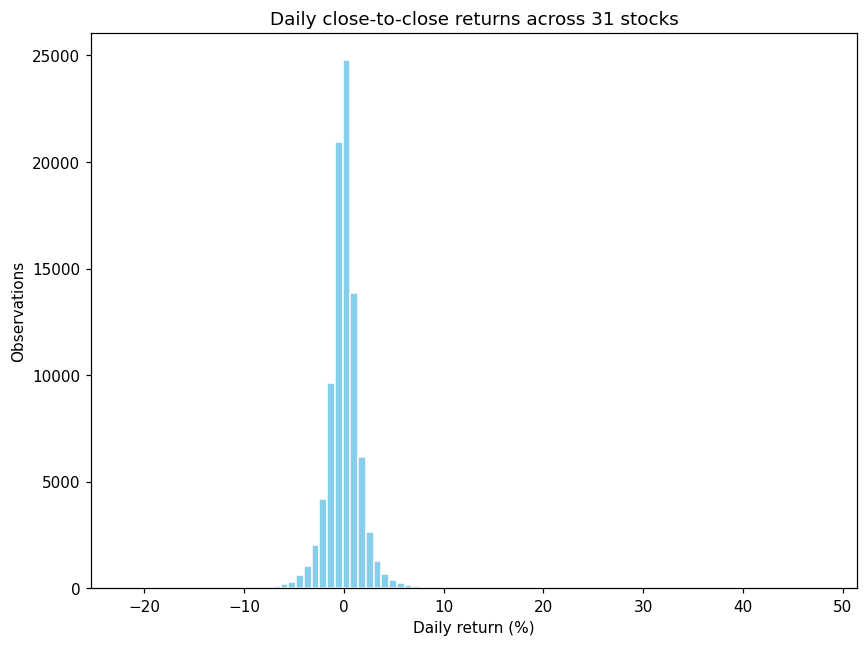

In [6]:
# True single-session percentage returns exclude changes spanning discarded market bars.
indicators = prepare_indicator_history(cleaned)
returns = indicators['Return'].dropna() * 100
plt.figure(figsize=(8, 6))
plt.hist(returns, bins=90, color='skyblue', edgecolor='white')
plt.title('Daily close-to-close returns across 31 stocks')
plt.xlabel('Daily return (%)')
plt.ylabel('Observations')
plt.tight_layout()
plt.show()


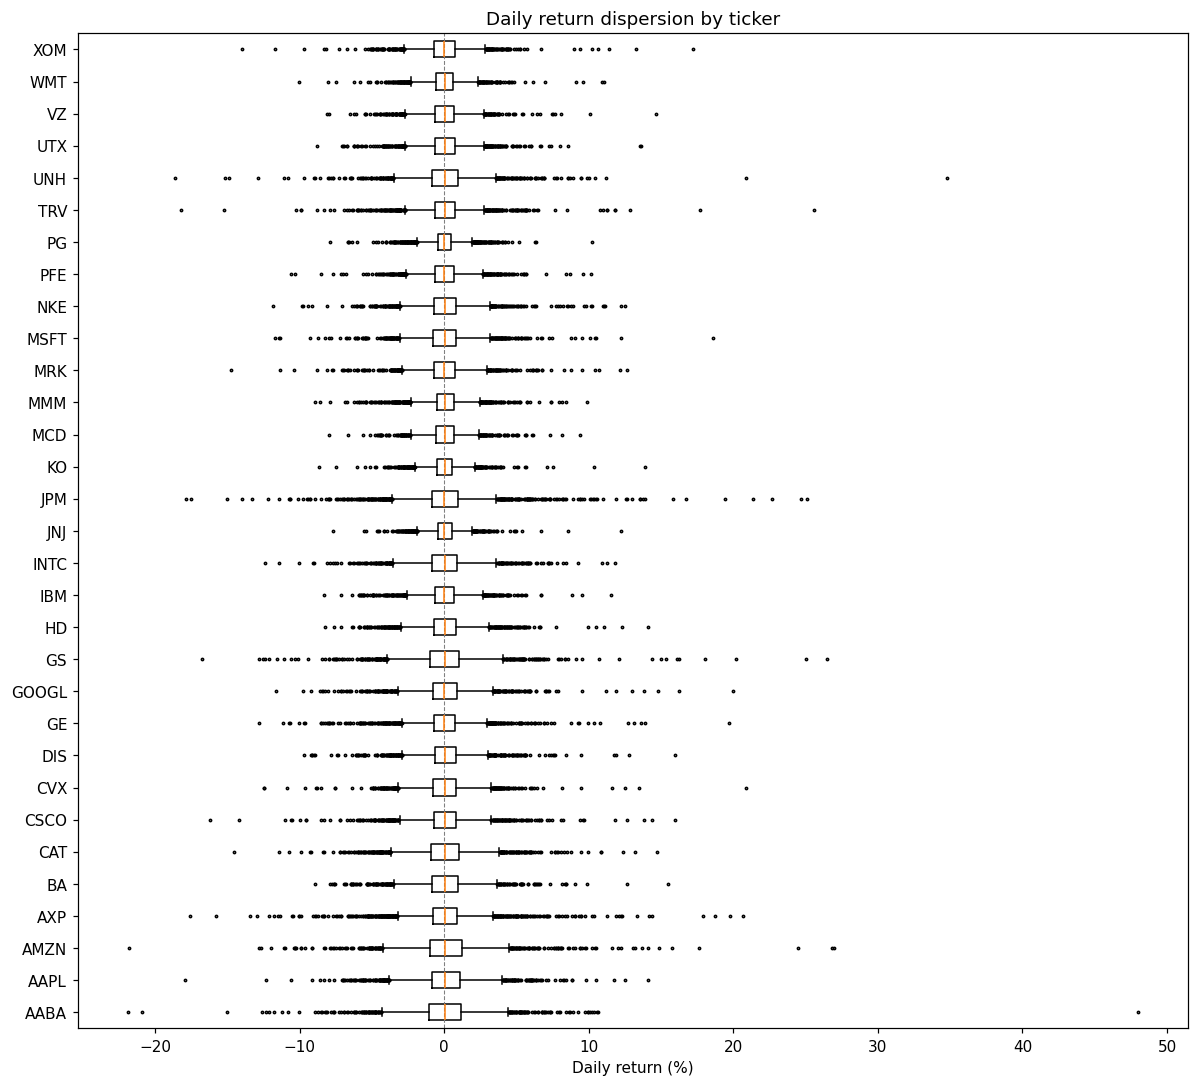

In [7]:
# Examine return dispersion within each ticker, never across nominal share prices.
symbols = sorted(cleaned['Name'].unique())
ticker_returns = [(group['Return'].dropna() * 100).to_numpy()
                  for _, group in indicators.groupby('Name', sort=True)]
fig, ax = plt.subplots(figsize=(11, 10))
ax.boxplot(ticker_returns, vert=False, flierprops={'markersize': 1.5})
ax.set_yticks(range(1, len(symbols) + 1), labels=symbols)
ax.set(title='Daily return dispersion by ticker', xlabel='Daily return (%)')
ax.axvline(0, color='gray', linewidth=0.7, linestyle='--')
plt.tight_layout()
plt.show()


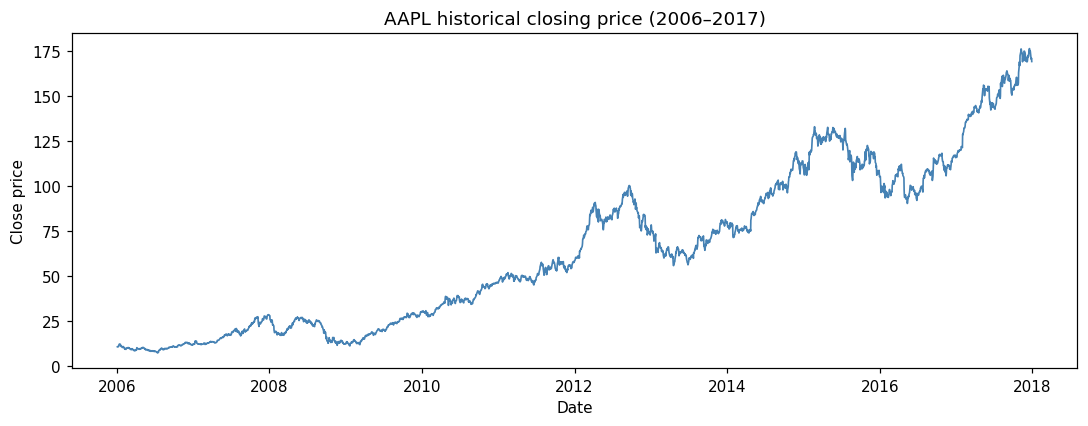

In [8]:
# Show the historical closing-price path for one representative symbol.
aapl = cleaned.loc[cleaned['Name'] == 'AAPL'].copy()
aapl = aapl.sort_values('Date')
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(aapl['Date'], aapl['Close'], linewidth=1.1, color='steelblue')
ax.set(title='AAPL historical closing price (2006–2017)', xlabel='Date', ylabel='Close price')
plt.tight_layout()
plt.show()

### Insights & Observations

- **Data Overview:** The 93,612 source records cover 31 stocks with Date, Open, High, Low, Close, Volume, and Name columns.
- **Data Quality:** The same OHLCV validator used for modeling retains 93,435 bars and excludes 177 incomplete or contradictory records. These records are not silently imputed.

- **Missing Values:** Open, High, and Low have 25, 10, and 20 missing entries respectively; the other columns have no missing entries.

- **Return Distribution:** Percentage returns place every ticker on a comparable scale. The histogram and per-ticker box plots use genuine consecutive-market-session returns; a gap created by an excluded bar is not mislabeled as a single-day change. Pooling raw share prices would incorrectly treat ordinary differences in stock price levels as outliers.
- **Historical Trend:** The AAPL closing-price series visualizes one symbol's price trajectory without mixing it with other tickers.

These observations will be used to refine our preprocessing steps and inform feature engineering for our trading agent.


## Conclusion

The exploratory analysis establishes that:
- The raw source contains 93,612 rows; quality checks retain 93,435 valid price bars.
- Percentage changes, rather than pooled nominal prices, support meaningful cross-ticker comparisons.
- The modeling pipeline excludes unreliable bars and constructs subsequent features from validated histories.
